# 02 – CSP + LDA baseline
Train on each subject's session T (day 1), test on session E (day 2).
Cross-session evaluation avoids leakage between nearby trials from the same recording.

In [1]:
import numpy as np
import pandas as pd
import scipy.io
import matplotlib.pyplot as plt
import mne
from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

DATA = "../data/BCICIV_2a_gdf"
LABELS = "../data/BCICIV_2a_gdf/true_labels"
CLASS_NAMES = ["left hand", "right hand", "feet", "tongue"]

mne.set_log_level("WARNING")

In [2]:
def load_session(subject, session):
    """Return X (trials, channels, time) and y (labels 1-4) for one session."""
    raw = mne.io.read_raw_gdf(f"{DATA}/A0{subject}{session}.gdf", preload=True, verbose="error")
    raw.set_channel_types({"EOG-left": "eog", "EOG-central": "eog", "EOG-right": "eog"})
    raw.pick("eeg")
    raw.filter(8.0, 30.0, verbose="error")

    events, event_id = mne.events_from_annotations(raw, verbose="error")
    # Session T marks cues as 769-772; session E marks every cue as 783 (class unknown)
    cue_codes = ["769", "770", "771", "772"] if session == "T" else ["783"]
    cue_ids = [event_id[c] for c in cue_codes if c in event_id]
    cue_events = events[np.isin(events[:, 2], cue_ids)]

    # Motor imagery runs from about 1 to 4 s after the cue; use 0.5-2.5 s
    epochs = mne.Epochs(raw, cue_events, tmin=0.5, tmax=2.5, baseline=None,
                        preload=True, verbose="error")
    X = epochs.get_data()
    y = scipy.io.loadmat(f"{LABELS}/A0{subject}{session}.mat")["classlabel"].ravel()
    assert len(X) == len(y), f"Subject {subject}{session}: {len(X)} trials but {len(y)} labels"
    return X, y

In [3]:
X_train, y_train = load_session(1, "T")
X_test, y_test = load_session(1, "E")
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (288, 22, 501)  Test: (288, 22, 501)


In [4]:
def make_model():
    return Pipeline([
        ("csp", CSP(n_components=6, log=True)),
        ("lda", LinearDiscriminantAnalysis()),
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(make_model(), X_train, y_train, cv=cv)
print(f"Within-session 5-fold accuracy (day 1 only): {cv_scores.mean():.3f}")

Within-session 5-fold accuracy (day 1 only): 0.788


Cross-session accuracy, subject 1: 0.771  (chance = 0.25)


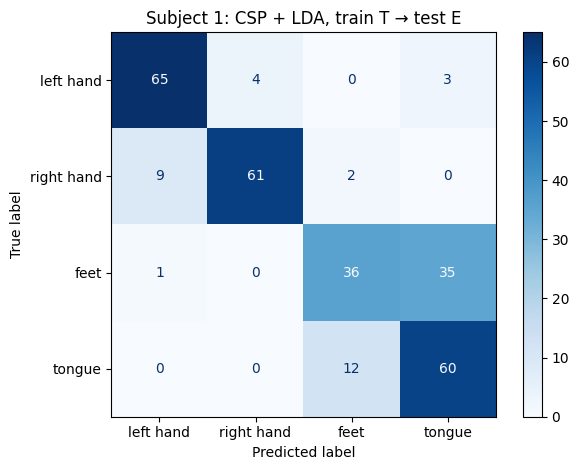

In [5]:
model = make_model()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(f"Cross-session accuracy, subject 1: {accuracy_score(y_test, y_pred):.3f}  (chance = 0.25)")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=CLASS_NAMES).plot(cmap="Blues")
plt.title("Subject 1: CSP + LDA, train T → test E")
plt.tight_layout()
plt.savefig("../figures/confusion_subject1.png", dpi=150)
plt.show()

In [6]:
results = []
for s in range(1, 10):
    Xtr, ytr = load_session(s, "T")
    Xte, yte = load_session(s, "E")
    m = make_model().fit(Xtr, ytr)
    acc = accuracy_score(yte, m.predict(Xte))
    results.append({"subject": s, "accuracy": acc})
    print(f"Subject {s}: {acc:.3f}")

df = pd.DataFrame(results)
print(f"\nMean accuracy: {df.accuracy.mean():.3f} ± {df.accuracy.std():.3f}")

Subject 1: 0.771
Subject 2: 0.455
Subject 3: 0.747
Subject 4: 0.545
Subject 5: 0.462
Subject 6: 0.451
Subject 7: 0.684
Subject 8: 0.778
Subject 9: 0.691

Mean accuracy: 0.620 ± 0.141


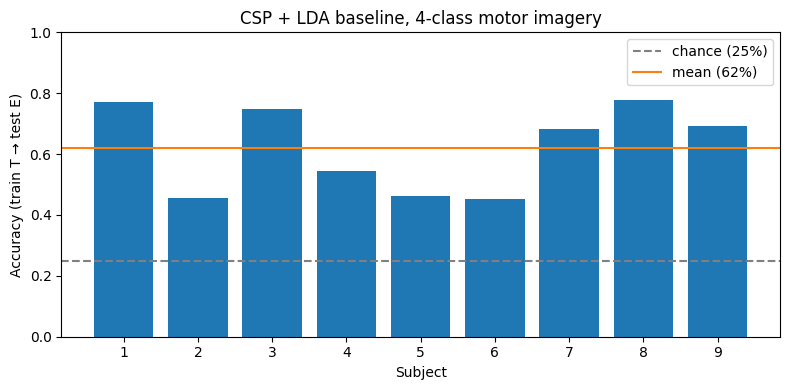

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(df.subject.astype(str), df.accuracy, color="tab:blue")
ax.axhline(0.25, color="gray", linestyle="--", label="chance (25%)")
ax.axhline(df.accuracy.mean(), color="tab:orange", label=f"mean ({df.accuracy.mean():.0%})")
ax.set_xlabel("Subject")
ax.set_ylabel("Accuracy (train T → test E)")
ax.set_ylim(0, 1)
ax.set_title("CSP + LDA baseline, 4-class motor imagery")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/csp_lda_per_subject.png", dpi=150)
plt.show()

## Results
- Mean cross-session accuracy (train day 1 → test day 2) across 9 subjects: 62.0% ± 14.1% (chance 25%).
- Performance varied widely: best subject 8 (77.8%), worst subject 6 (45.1%). Five subjects scored 68–78% and four scored 45–55%, a common split in motor imagery BCIs.
- For subject 1, within-session accuracy on day 1 (5-fold CV) was 78.8% vs. 77.1% when testing on day 2, a small cross-session drop for this subject.
- Most common confusion (subject 1): feet trials misclassified as tongue (35 of 72). Left- and right-hand imagery, which produce lateralized patterns over C3 and C4, were classified more accurately (85–90%) than feet (50%).
- Next: EEGNet in PyTorch, compared against this baseline.